INFO:root:building '_cython_magic_ddb5f51d8346184dbf71f76a8dc37cbb' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_ddb5f51d8346184dbf71f76a8dc37cbb.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_ddb5f51d8346184dbf71f76a8dc37cbb.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_ddb5f51d8346184dbf71f76a8dc37cbb.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 4. s
[1000 ms]  rates (mean): 224.2 Hz  
[1100 ms]  rates (mean): 222.2 Hz  
[1200 ms]  rates (mean): 217.8 Hz  
[1300 ms]  rates (mean): 211.0 Hz  
[1400 ms]  rates (mean): 202.6 Hz  
[1500 ms]  rates (mean): 190.3 Hz  
[1600 ms]  rates (mean): 175.6 Hz  
[1700 ms]  rates (mean): 158.4 Hz  
[1800 ms]  rates (mean): 139.9 Hz  
1.8001 s (45%) simulated in 10s, estimated 13s remaining.
[1900 ms]  rates (mean): 119.8 Hz  
[2000 ms]  rates (mean): 99.1 Hz  
[2100 ms]  rates (mean): 79.3 Hz  
[2200 ms]  rates (mean): 61.5 Hz  
[2300 ms]  rates (mean): 46.2 Hz  
[2400 ms]  rates (mean): 32.2 Hz  
[2500 ms]  rates (mean): 21.9 Hz  
[2600 ms]  rates (mean): 14.4 Hz  
[2700 ms]  rates (mean): 9.0 Hz  
[2800 ms]  rates (mean): 5.2 Hz  
2.8001 s (70%) simulated in 21s, estimated 9s remaining.
[2900 ms]  rates (mean): 2.9 Hz  
[3000 ms]  rates (mean): 1.4 Hz  
[3100 ms]  rates (mean): 0.8 Hz  
[3200 ms]  rates (mean): 0.5 Hz  
[3300 ms]  rates (mean)

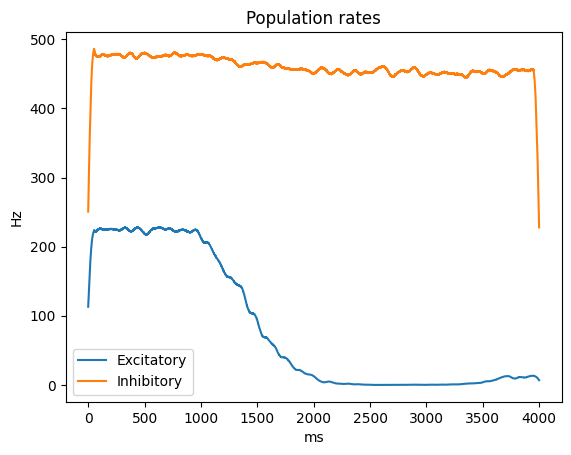

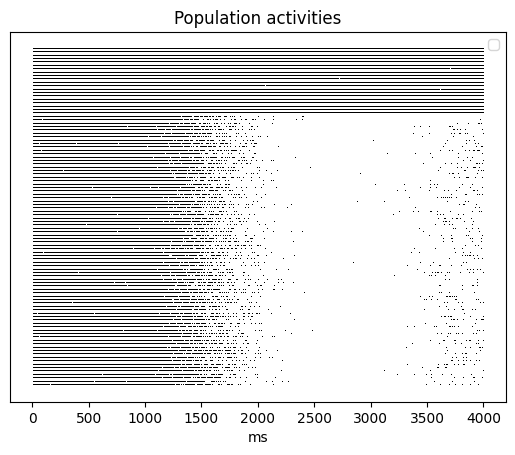

Text(0.5, 1.0, 'Recurrent connections')

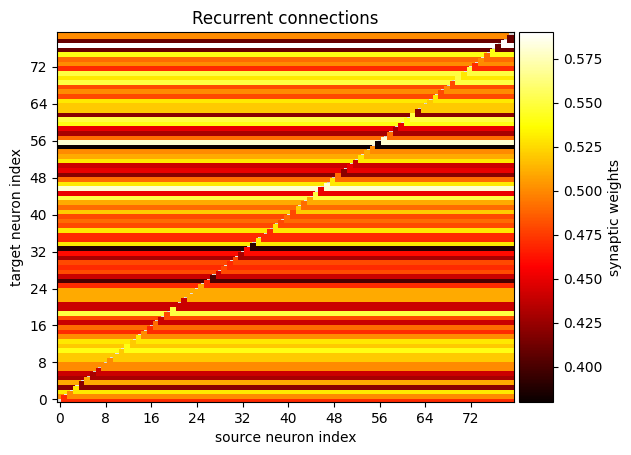

In [10]:
from brian2 import *
from brian2tools import *

start_scope()

# populations
N = 100
N_E = int(N * 0.8)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons
target_rate = 5*Hz
alpha = 0.05
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 20 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS * 80. / N_E
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS * 80. / N_E
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 1.25 * nS * 20. / N_I
g_GABA_I = 0.973 * nS * 20. / N_I
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L


eqs_pre_glut = '''
s_AMPA += w
'''

eqs_pre_gaba = '''
s_GABA += w
'''

# E to E
C_E_E = Synapses(P_E, P_E, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1


# E to I
C_E_I = Synapses(P_E, P_I, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_I.connect()
C_E_I.w[:] = 1

# I to I
C_I_I = Synapses(P_I, P_I, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1

# I to E
C_I_E = Synapses(P_I, P_E, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_E.connect()
C_I_E.w[:] = 1

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


# monitors

sp_E = SpikeMonitor(P_E)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_I = PopulationRateMonitor(P_I)


@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    times = sp_E.t
    idxs  = sp_E.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 3)
        for pre in range(N_I):
            C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - 1*alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")



net = Network(collect())
net.run(4 * second, report='stdout')

# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()

ax = plot_synapses(C_E_E.i, C_E_E.j, C_E_E.w, var_name='synaptic weights',
                   plot_type='scatter', cmap='hot')
add_background_pattern(ax)
ax.set_title('Recurrent connections')



INFO:root:building '_cython_magic_a94ca3b3870db7d5bd4eef51b36eb861' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_a94ca3b3870db7d5bd4eef51b36eb861.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_a94ca3b3870db7d5bd4eef51b36eb861.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_a94ca3b3870db7d5bd4eef51b36eb861.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 8. s
[1000 ms]  rates (mean): 223.9 Hz  
[1100 ms]  rates (mean): 221.4 Hz  
[1200 ms]  rates (mean): 216.5 Hz  
[1300 ms]  rates (mean): 209.8 Hz  
[1400 ms]  rates (mean): 200.4 Hz  
[1500 ms]  rates (mean): 187.9 Hz  
[1600 ms]  rates (mean): 172.7 Hz  
1.6001 s (20%) simulated in 10s, estimated 42s remaining.
[1700 ms]  rates (mean): 155.9 Hz  
[1800 ms]  rates (mean): 137.1 Hz  
[1900 ms]  rates (mean): 116.8 Hz  
[2000 ms]  rates (mean): 96.5 Hz  
[2100 ms]  rates (mean): 76.7 Hz  
[2200 ms]  rates (mean): 59.5 Hz  
[2300 ms]  rates (mean): 44.2 Hz  
[2400 ms]  rates (mean): 31.5 Hz  
2.4001 s (30%) simulated in 20s, estimated 48s remaining.
[2500 ms]  rates (mean): 21.7 Hz  
[2600 ms]  rates (mean): 14.2 Hz  
[2700 ms]  rates (mean): 8.3 Hz  
[2800 ms]  rates (mean): 4.9 Hz  
[2900 ms]  rates (mean): 2.6 Hz  
[3000 ms]  rates (mean): 1.1 Hz  
[3100 ms]  rates (mean): 0.5 Hz  
[3200 ms]  rates (mean): 0.3 Hz  
3.2001 s (40%) simulat

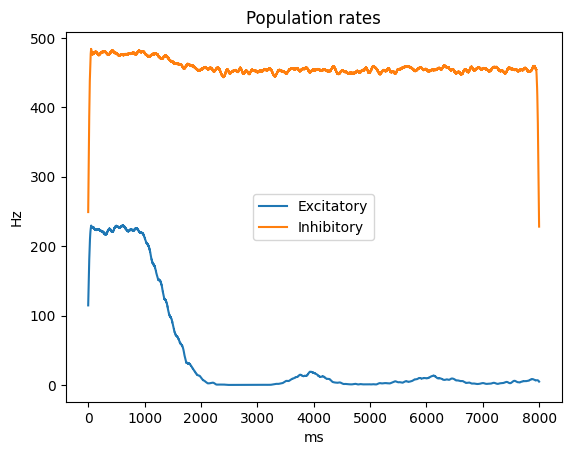

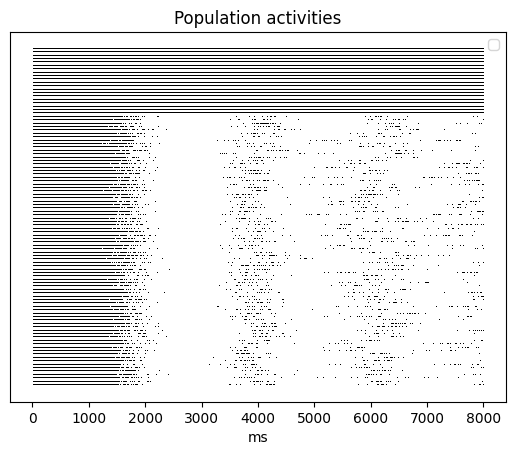

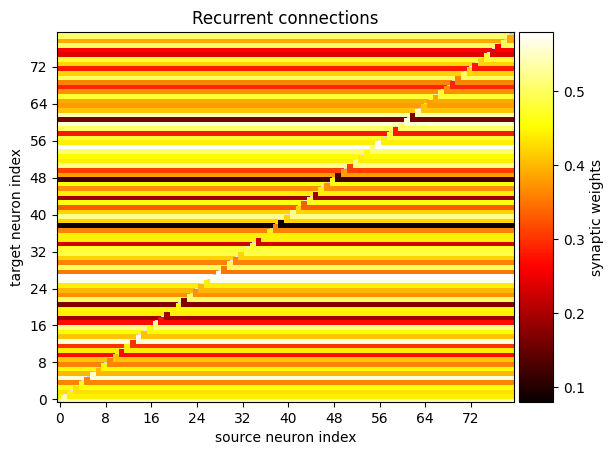

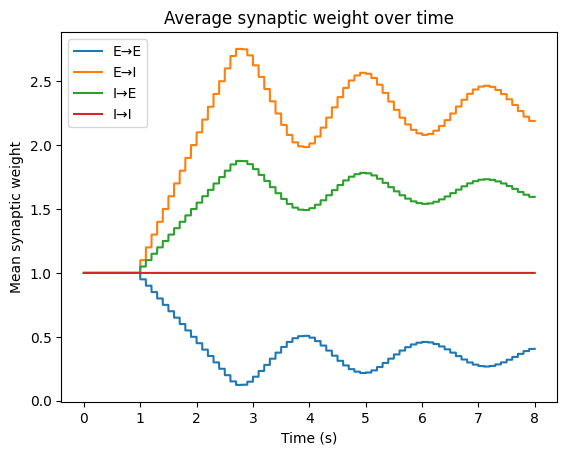

In [21]:
from brian2 import *
from brian2tools import *

start_scope()

# populations
N = 100
N_E = int(N * 0.8)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons
target_rate = 5*Hz
alpha = 0.05
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 20 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS * 80. / N_E
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS * 80. / N_E
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 1.25 * nS * 20. / N_I
g_GABA_I = 0.973 * nS * 20. / N_I
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L


eqs_pre_glut = '''
s_AMPA += w
'''

eqs_pre_gaba = '''
s_GABA += w
'''

# E to E
C_E_E = Synapses(P_E, P_E, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1


# E to I
C_E_I = Synapses(P_E, P_I, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_I.connect()
C_E_I.w[:] = 1

# I to I
C_I_I = Synapses(P_I, P_I, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1

# I to E
C_I_E = Synapses(P_I, P_E, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_E.connect()
C_I_E.w[:] = 1

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


# monitors

sp_E = SpikeMonitor(P_E)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)


@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    times = sp_E.t
    idxs  = sp_E.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 3)
        for pre in range(N_I):
            C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - 2*alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")



net = Network(collect())
net.run(8 * second, report='stdout')

# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()

ax = plot_synapses(C_E_E.i, C_E_E.j, C_E_E.w, var_name='synaptic weights',
                   plot_type='scatter', cmap='hot')
add_background_pattern(ax)
ax.set_title('Recurrent connections')

import matplotlib.pyplot as plt

def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)
    
plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()



INFO:root:building '_cython_magic_07f696826878b9cf22779bac4718aa1f' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_07f696826878b9cf22779bac4718aa1f.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_07f696826878b9cf22779bac4718aa1f.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_07f696826878b9cf22779bac4718aa1f.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 8. s
[1000 ms]  rates (mean): 7.2 Hz  
[1100 ms]  rates (mean): 7.4 Hz  
[1200 ms]  rates (mean): 7.5 Hz  
[1300 ms]  rates (mean): 7.7 Hz  
[1400 ms]  rates (mean): 8.2 Hz  
[1500 ms]  rates (mean): 8.8 Hz  
1.5001 s (18%) simulated in 10s, estimated 46s remaining.
[1600 ms]  rates (mean): 9.1 Hz  
[1700 ms]  rates (mean): 9.5 Hz  
[1800 ms]  rates (mean): 9.9 Hz  
[1900 ms]  rates (mean): 10.6 Hz  
[2000 ms]  rates (mean): 11.1 Hz  
[2100 ms]  rates (mean): 11.9 Hz  
[2200 ms]  rates (mean): 12.8 Hz  
[2300 ms]  rates (mean): 13.7 Hz  
[2400 ms]  rates (mean): 14.1 Hz  
2.4001 s (30%) simulated in 21s, estimated 50s remaining.
[2500 ms]  rates (mean): 14.6 Hz  
[2600 ms]  rates (mean): 15.6 Hz  
[2700 ms]  rates (mean): 16.4 Hz  
[2800 ms]  rates (mean): 16.9 Hz  
[2900 ms]  rates (mean): 16.9 Hz  
[3000 ms]  rates (mean): 17.3 Hz  
[3100 ms]  rates (mean): 17.6 Hz  
[3200 ms]  rates (mean): 17.7 Hz  
3.2001 s (40%) simulated in 31s, es

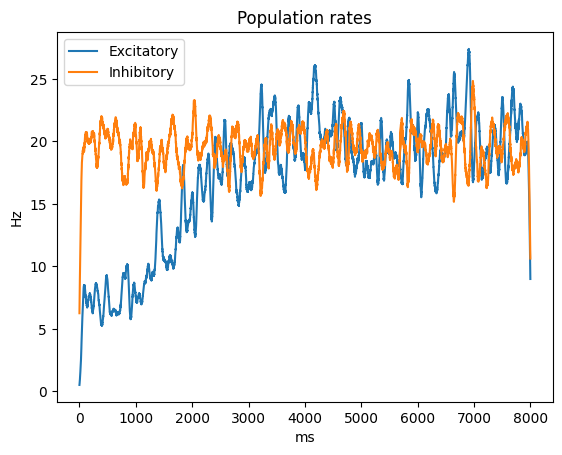

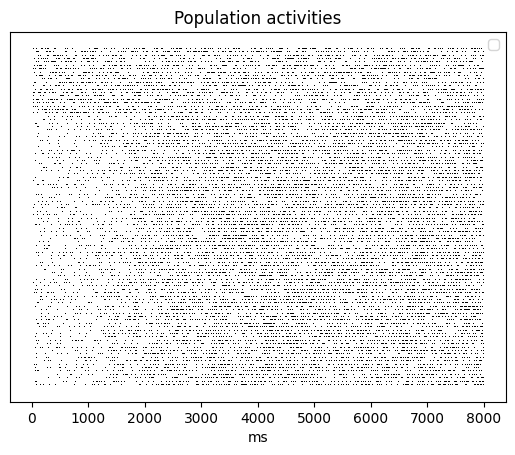

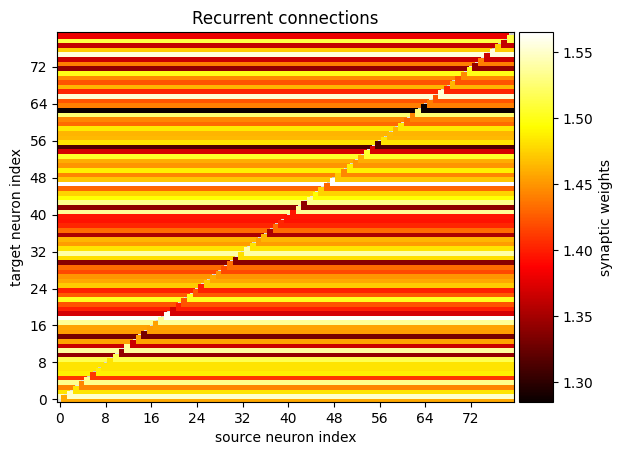

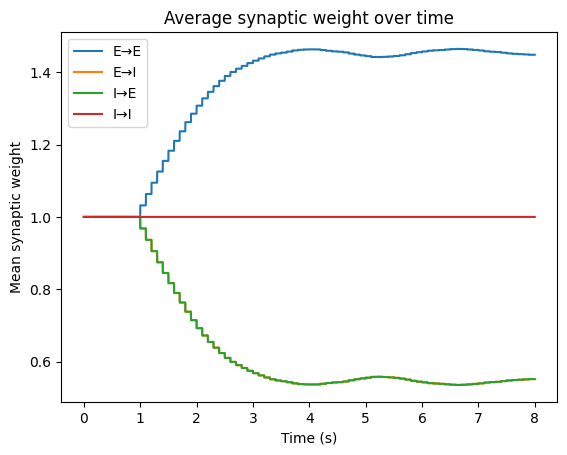

In [23]:
from brian2 import *
from brian2tools import *

start_scope()

# populations
N = 100
N_E = int(N * 0.8)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons
target_rate = 20*Hz
alpha = 0.05
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS * 80. / N_E
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS * 80. / N_E
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 1.25 * nS * 20. / N_I
g_GABA_I = 0.973 * nS * 20. / N_I
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L


eqs_pre_glut = '''
s_AMPA += w
'''

eqs_pre_gaba = '''
s_GABA += w
'''

# E to E
C_E_E = Synapses(P_E, P_E, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1


# E to I
C_E_I = Synapses(P_E, P_I, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_I.connect()
C_E_I.w[:] = 1

# I to I
C_I_I = Synapses(P_I, P_I, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1

# I to E
C_I_E = Synapses(P_I, P_E, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_E.connect()
C_I_E.w[:] = 1

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


# monitors

sp_E = SpikeMonitor(P_E)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)

@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    times = sp_E.t
    idxs  = sp_E.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 3)
        for pre in range(N_I):
            C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")



net = Network(collect())
net.run(8 * second, report='stdout')

# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()

ax = plot_synapses(C_E_E.i, C_E_E.j, C_E_E.w, var_name='synaptic weights',
                   plot_type='scatter', cmap='hot')
add_background_pattern(ax)
ax.set_title('Recurrent connections')

import matplotlib.pyplot as plt

def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)

plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()



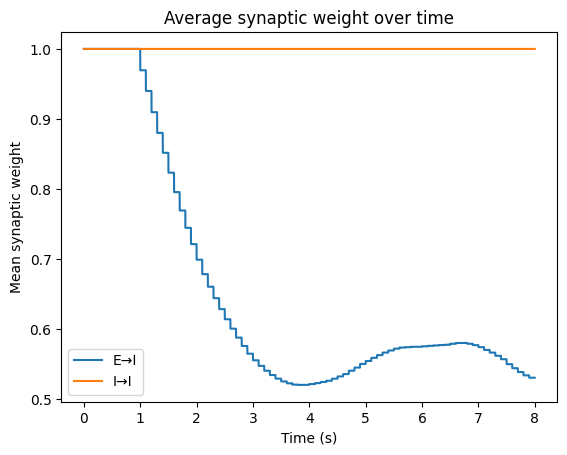

In [19]:
plt.figure()
#plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
#plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()

INFO:root:building '_cython_magic_474ea5b802d6923e38af7aaedec8f5ce' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_474ea5b802d6923e38af7aaedec8f5ce.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_474ea5b802d6923e38af7aaedec8f5ce.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_474ea5b802d6923e38af7aaedec8f5ce.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 4. s
[1000 ms]  rates (mean): 8.0 Hz  
[1000 ms]  rates (mean): 0.3 Hz  
[1100 ms]  rates (mean): 8.2 Hz  
[1100 ms]  rates (mean): 0.4 Hz  
[1200 ms]  rates (mean): 8.3 Hz  
[1200 ms]  rates (mean): 0.4 Hz  
1.2001 s (30%) simulated in 12s, estimated 30s remaining.
[1300 ms]  rates (mean): 8.4 Hz  
[1300 ms]  rates (mean): 0.5 Hz  
[1400 ms]  rates (mean): 8.8 Hz  
[1400 ms]  rates (mean): 0.7 Hz  
[1500 ms]  rates (mean): 9.7 Hz  
[1500 ms]  rates (mean): 1.0 Hz  
1.594 s (39%) simulated in 22s, estimated 34s remaining.
[1600 ms]  rates (mean): 10.4 Hz  
[1600 ms]  rates (mean): 1.2 Hz  
[1700 ms]  rates (mean): 11.5 Hz  
[1700 ms]  rates (mean): 1.8 Hz  
[1800 ms]  rates (mean): 12.4 Hz  
[1800 ms]  rates (mean): 2.6 Hz  
1.8001 s (45%) simulated in 33s, estimated 41s remaining.
[1900 ms]  rates (mean): 13.5 Hz  
[1900 ms]  rates (mean): 3.9 Hz  
[2000 ms]  rates (mean): 15.1 Hz  
[2000 ms]  rates (mean): 6.0 Hz  
[2100 ms]  rates (mea

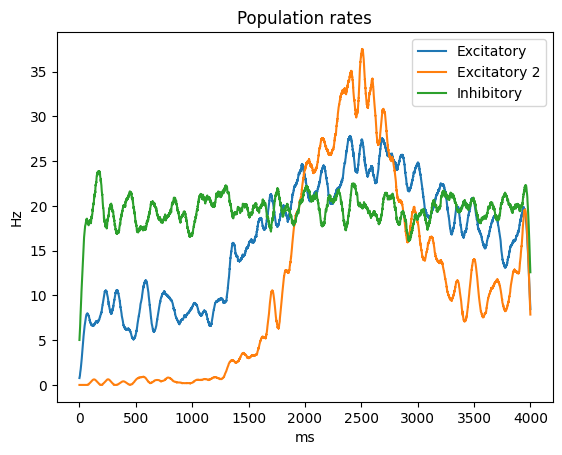

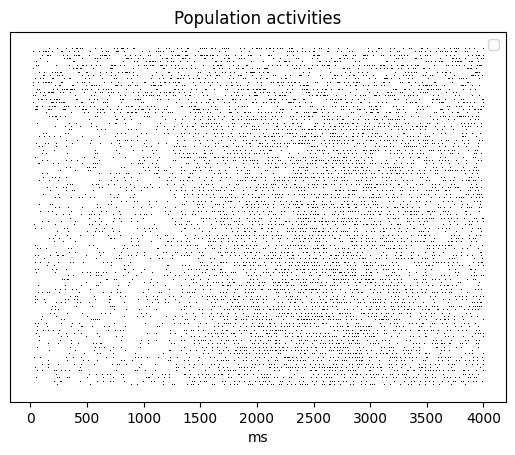

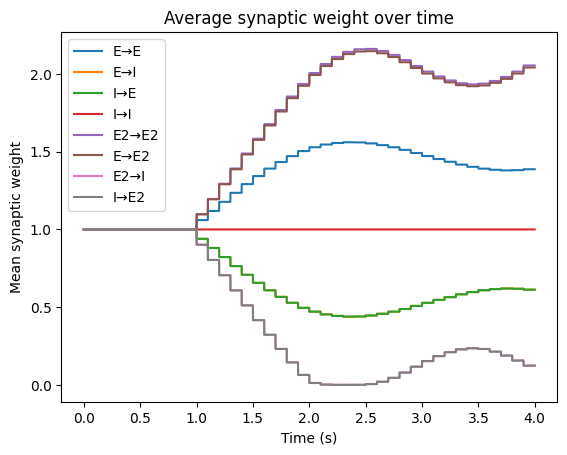

WARNING    /tmp/ipykernel_22917/3742711019.py:262: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_22917/3742711019.py:263: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)

WARNING    /tmp/ipykernel_22917/3742711019.py:264: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keywo

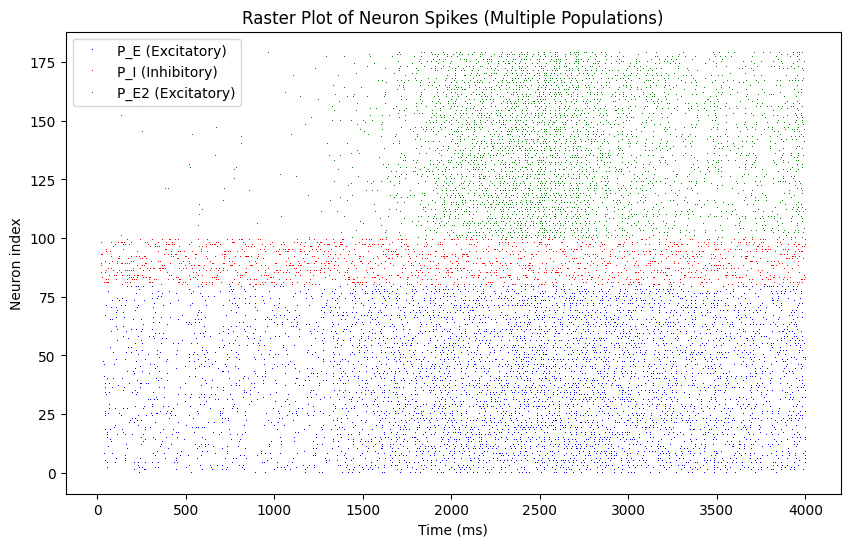

In [7]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt

start_scope()

# populations
N = 100
N_E = int(N * 0.8)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons
target_rate = 20*Hz
alpha = 0.1 #0.05
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS * 80. / N_E
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS * 80. / N_E
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 1.25 * nS * 20. / N_I
g_GABA_I = 0.973 * nS * 20. / N_I
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_E2 = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E2.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L


eqs_pre_glut = '''
s_AMPA += w
'''

eqs_pre_gaba = '''
s_GABA += w
'''
#E1
# E to E
C_E_E = Synapses(P_E, P_E, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1


# E to I
C_E_I = Synapses(P_E, P_I, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_I.connect()
C_E_I.w[:] = 1

# I to I
C_I_I = Synapses(P_I, P_I, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1

# I to E
C_I_E = Synapses(P_I, P_E, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_E.connect()
C_I_E.w[:] = 1

#E2
# E1 to E2
C_E_E2 = Synapses(P_E, P_E2, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E_E2.connect()
C_E_E2.w[:] = 1

# E2 to E2
C_E2_E2 = Synapses(P_E2, P_E2, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E2_E2.connect('i != j')
C_E2_E2.w[:] = 1


# E2 to I
C_E2_I = Synapses(P_E2, P_I, model= 'w : 1', on_pre=eqs_pre_glut, method='euler')
C_E2_I.connect()
C_E2_I.w[:] = 1

# I to E2
C_I_E2 = Synapses(P_I, P_E2, model= 'w : 1', on_pre=eqs_pre_gaba, method='euler')
C_I_E2.connect()
C_I_E2.w[:] = 1

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_E2 = PoissonInput(P_E2, 's_AMPA_ext', C_ext, 2.5*Hz, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


# monitors

sp_E = SpikeMonitor(P_E)
sp_E2 = SpikeMonitor(P_E2)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_E2 = PopulationRateMonitor(P_E2)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)
mon_C_E_E2 = StateMonitor(C_E_E2, 'w', record=True)
mon_C_E2_E2 = StateMonitor(C_E2_E2, 'w', record=True)
mon_C_E2_I = StateMonitor(C_E2_I, 'w', record=True)
mon_C_I_E2 = StateMonitor(C_I_E2, 'w', record=True)



@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    #E
    times = sp_E.t
    idxs  = sp_E.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 3)
        for pre in range(N_I):
            C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
    #E2
    times = sp_E2.t
    idxs  = sp_E2.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E2_E2.w[pre, post] = clip(C_E2_E2.w[pre, post]+ alpha * delta, 0, 5)
            C_E_E2.w[pre,post] = clip(C_E_E2.w[pre, post]+ alpha * delta, 0, 5)
        for pre in range(N_I):
            C_I_E2.w[pre, post] = clip(C_I_E2.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E2_I.w[post, pre] = clip(C_E2_I.w[post, pre] - alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")


net = Network(collect())
net.run(4 * second, report='stdout')

# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_E2.t / ms, r_E2.smooth_rate(width=25 * ms) / Hz, label='Excitatory 2')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()

# ax = plot_synapses(C_E_E.i, C_E_E.j, C_E_E.w, var_name='synaptic weights',
#                    plot_type='scatter', cmap='hot')
# add_background_pattern(ax)
# ax.set_title('Recurrent connections')


def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)

plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plot_mean_weight(mon_C_E2_E2, 'E2→E2')
plot_mean_weight(mon_C_E_E2, 'E→E2')
plot_mean_weight(mon_C_E2_I, 'E2→I')
plot_mean_weight(mon_C_I_E2, 'I→E2')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.plot(sp_E2.t / ms, sp_E2.i + N_E+N_I, ',k', label='P_E2 (Excitatory)', color='green', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()


WARNING    /tmp/ipykernel_962/2820622899.py:2: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_962/2820622899.py:3: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)

WARNING    /tmp/ipykernel_962/2820622899.py:4: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument 

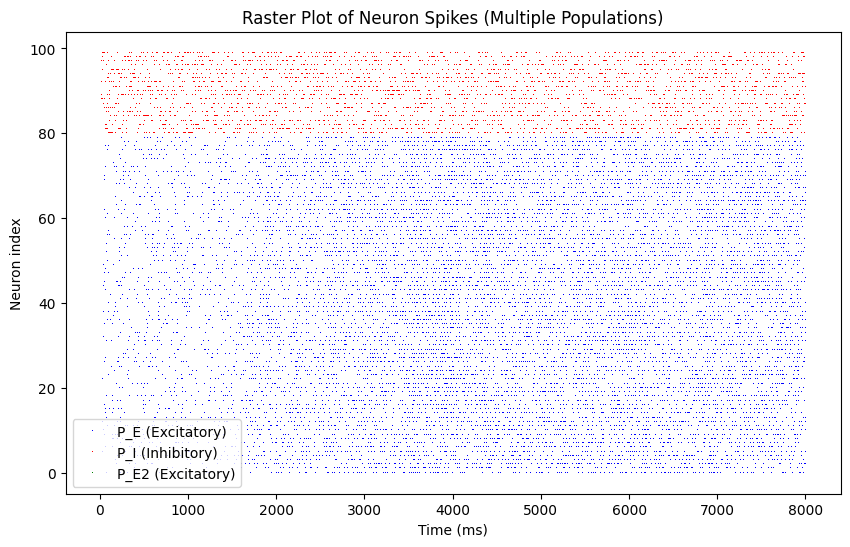

In [2]:
plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.plot(sp_E2.t / ms, sp_E2.i + N_E+N_I, ',k', label='P_E2 (Excitatory)', color='green', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()